**Перед выполнением ячеек переключитесь на среду выполнения с графическим процессором.**

# **Практическое занятие: Вариационный автоэнкодер (VAE)**

В этом практическом занятии мы реализуем и обучим вариационный автоэнкодер (VAE) на датасете рукописных цифр MNIST. Вы познакомитесь с основными компонентами VAE: энкодером, декодером, репараметризацией и функцией потерь (ELBO). После обучения мы визуализируем результаты: реконструкции, случайные генерации, интерполяции и исследуем влияние гиперпараметров.

👈 *Цель занятия — не просто запустить готовый код, а понять, как устроен VAE внутри, и поэкспериментировать с ним.*

## 1. Импорт библиотек и подготовка данных

Нам понадобятся PyTorch, Torchvision для работы с данными, Matplotlib для визуализации и NumPy.

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

# Устройство (GPU если доступно)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### 1.1 Загрузка датасета MNIST

Мы используем MNIST — 28x28 чёрно-белые изображения цифр. Нормализуем пиксели к интервалу [0,1].

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 491kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.3MB/s]


Train size: 60000, Test size: 10000


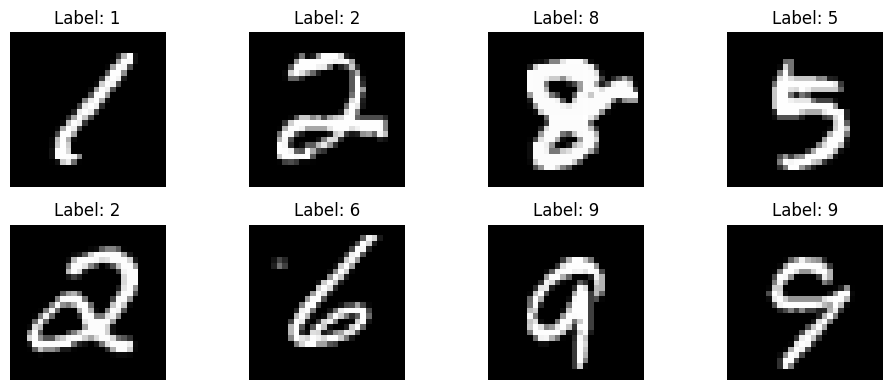

In [11]:
transform = transforms.Compose([
    transforms.ToTensor(),
    # transforms.Normalize((0.5,), (0.5,))  # Не нормализуем, оставляем [0,1] для BCE
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train size: {len(train_dataset)}, Test size: {len(test_dataset)}")

# Посмотрим на несколько примеров
examples = iter(train_loader)
images, labels = next(examples)
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.title(f"Label: {labels[i].item()}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Определение модели VAE

Класс VAE содержит:
- **Энкодер**: полносвязная сеть, которая преобразует входное изображение (784 пикселя) в параметры распределения $q(z|x)$: среднее `mu` и логарифм дисперсии `log_var`.
- **Reparameterization trick**: позволяет дифференцировать случайный узел: $z = \mu + \sigma \cdot \varepsilon$, где $\varepsilon \sim \mathcal{N}(0, I)$.
- **Декодер**: полносвязная сеть, которая по латентному коду $z$ восстанавливает изображение. На выходе используем сигмоиду, чтобы пиксели были в [0,1].

In [12]:
class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=256, latent_dim=20):
        super(VAE, self).__init__()

        # Энкодер
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2 * latent_dim)  # выход: mu и log_var
        )

        # Декодер
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()  # чтобы выход был в [0,1]
        )

        self.latent_dim = latent_dim

    def encode(self, x):
        """Возвращает mu и log_var"""
        h = self.encoder(x)
        mu, log_var = h.chunk(2, dim=-1)
        return mu, log_var

    def reparameterize(self, mu, log_var):
        """Репараметризация: z = mu + sigma * eps"""
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        recon = self.decode(z)
        return recon, mu, log_var

### 2.1 Функция потерь (ELBO)

Для VAE мы максимизируем нижнюю границу логарифма правдоподобия (ELBO). На практике минимизируем отрицательный ELBO:

$$ \mathcal{L}_{VAE} = -\mathbb{E}_{z\sim q_\phi(z|x)}[\log p_\theta(x|z)] + D_{KL}(q_\phi(z|x) \| p(z)) $$

где $p(z) = \mathcal{N}(0, I)$. Первое слагаемое — reconstruction loss (BCE или MSE), второе — KL-дивергенция между распределением энкодера и стандартным нормальным.

Для нормальных распределений с диагональной ковариацией KL имеет аналитическую форму:

$$ D_{KL} = -\frac{1}{2} \sum_{j=1}^{M} (1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2) $$

In [13]:
def vae_loss(recon_x, x, mu, log_var, beta=1.0):
    """
    recon_x: восстановленное изображение
    x: исходное изображение
    mu, log_var: параметры распределения энкодера
    beta: коэффициент для KL (β-VAE)
    """
    # Reconstruction loss (Binary Cross Entropy, сумма по пикселям и батчу)
    BCE = F.binary_cross_entropy(recon_x, x, reduction='sum')

    # KL divergence
    KL = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())

    # Усредняем по батчу (или можно оставить сумму, главное — консистентность)
    return (BCE + beta * KL) / x.size(0)

## 3. Обучение VAE

Обучим модель на 10-20 эпохах. Будем логировать значения loss и визуализировать прогресс.

In [14]:
# Параметры
latent_dim = 2
hidden_dim = 256
lr = 1e-3
num_epochs = 15
beta = 1.0  # для обычного VAE β=1

model = VAE(input_dim=784, hidden_dim=hidden_dim, latent_dim=latent_dim).to(device)
optimizer = optim.Adam(model.parameters(), lr=lr)

train_losses = []
test_losses = []

Epoch 1: 100%|██████████| 469/469 [00:07<00:00, 60.57it/s]


Epoch 1: Train Loss = 189.2707, Test Loss = 167.5470


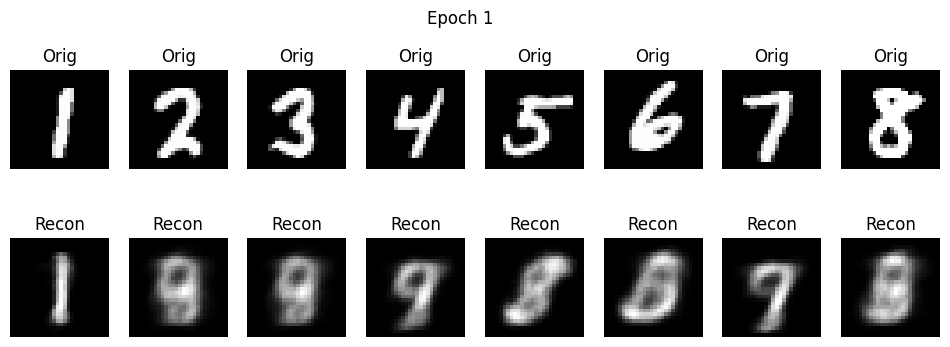

Epoch 2: 100%|██████████| 469/469 [00:08<00:00, 57.50it/s]


Epoch 2: Train Loss = 163.2290, Test Loss = 159.3942


Epoch 3: 100%|██████████| 469/469 [00:07<00:00, 61.91it/s]


Epoch 3: Train Loss = 156.9147, Test Loss = 154.7731


Epoch 4: 100%|██████████| 469/469 [00:07<00:00, 61.37it/s]


Epoch 4: Train Loss = 153.5991, Test Loss = 152.4699


Epoch 5: 100%|██████████| 469/469 [00:07<00:00, 62.06it/s]


Epoch 5: Train Loss = 151.3437, Test Loss = 150.6115


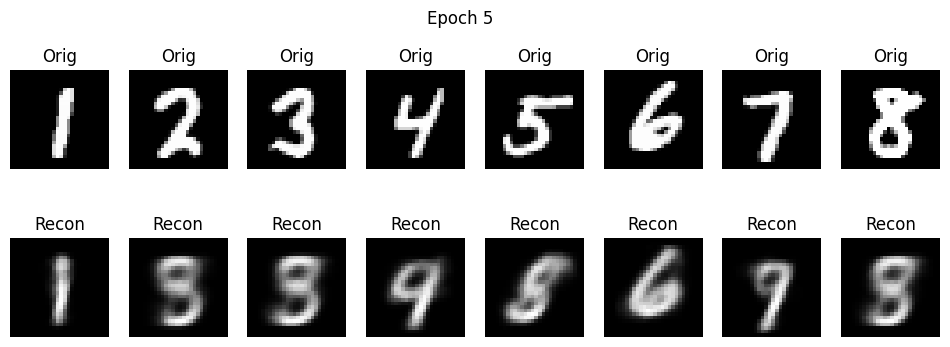

Epoch 6: 100%|██████████| 469/469 [00:07<00:00, 61.39it/s]


Epoch 6: Train Loss = 149.7109, Test Loss = 149.3557


Epoch 7: 100%|██████████| 469/469 [00:07<00:00, 61.70it/s]


Epoch 7: Train Loss = 148.2022, Test Loss = 147.8334


Epoch 8: 100%|██████████| 469/469 [00:07<00:00, 61.80it/s]


Epoch 8: Train Loss = 147.1658, Test Loss = 147.0396


Epoch 9: 100%|██████████| 469/469 [00:07<00:00, 61.68it/s]


Epoch 9: Train Loss = 146.0817, Test Loss = 146.6274


Epoch 10: 100%|██████████| 469/469 [00:07<00:00, 61.52it/s]


Epoch 10: Train Loss = 145.2306, Test Loss = 145.5034


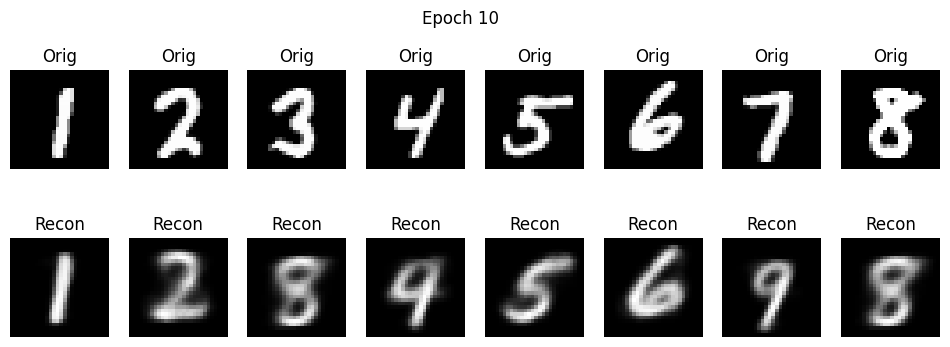

Epoch 11: 100%|██████████| 469/469 [00:08<00:00, 58.08it/s]


Epoch 11: Train Loss = 144.5675, Test Loss = 144.9635


Epoch 12: 100%|██████████| 469/469 [00:07<00:00, 59.26it/s]


Epoch 12: Train Loss = 144.0805, Test Loss = 144.5799


Epoch 13: 100%|██████████| 469/469 [00:08<00:00, 56.39it/s]


Epoch 13: Train Loss = 143.3450, Test Loss = 143.6134


Epoch 14: 100%|██████████| 469/469 [00:07<00:00, 60.70it/s]


Epoch 14: Train Loss = 142.8322, Test Loss = 143.4922


Epoch 15: 100%|██████████| 469/469 [00:07<00:00, 61.96it/s]


Epoch 15: Train Loss = 142.4101, Test Loss = 143.3779


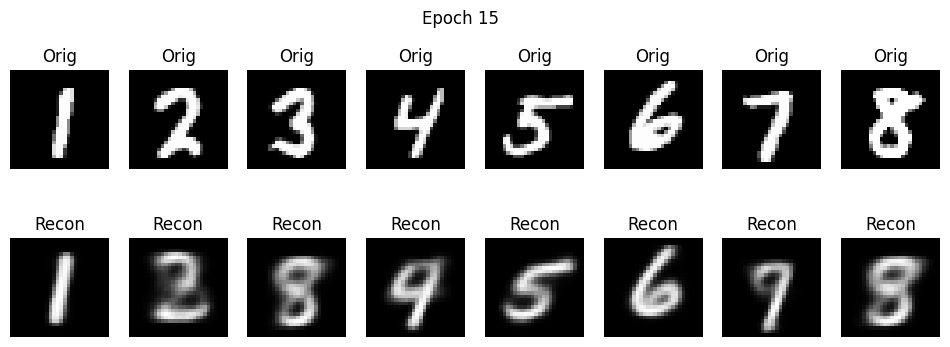

In [15]:
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for batch_idx, (data, _) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}")):
        data = data.view(data.size(0), -1).to(device)  # flatten
        optimizer.zero_grad()
        recon, mu, log_var = model(data)
        loss = vae_loss(recon, data, mu, log_var, beta)
        loss.backward()
        total_loss += loss.item() * data.size(0)
        optimizer.step()

    avg_train_loss = total_loss / len(train_loader.dataset)
    train_losses.append(avg_train_loss)

    # Оценка на тесте
    model.eval()
    total_test_loss = 0
    with torch.no_grad():
        for data, _ in test_loader:
            data = data.view(data.size(0), -1).to(device)
            recon, mu, log_var = model(data)
            loss = vae_loss(recon, data, mu, log_var, beta)
            total_test_loss += loss.item() * data.size(0)
    avg_test_loss = total_test_loss / len(test_loader.dataset)
    test_losses.append(avg_test_loss)

    print(f'Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Test Loss = {avg_test_loss:.4f}')

    # Визуализируем реконструкции в конце каждой эпохи (первые 8)
    if (epoch+1) % 5 == 0 or epoch == 0:
        model.eval()
        with torch.no_grad():
            sample_data = data[:8]
            recon_sample = recon[:8]
            plt.figure(figsize=(12,4))
            for i in range(8):
                plt.subplot(2,8,i+1)
                plt.imshow(sample_data[i].cpu().view(28,28), cmap='gray')
                plt.axis('off')
                plt.title('Orig')
                plt.subplot(2,8,i+9)
                plt.imshow(recon_sample[i].cpu().view(28,28), cmap='gray')
                plt.axis('off')
                plt.title('Recon')
            plt.suptitle(f'Epoch {epoch+1}')
            plt.show()

### 3.1 График обучения

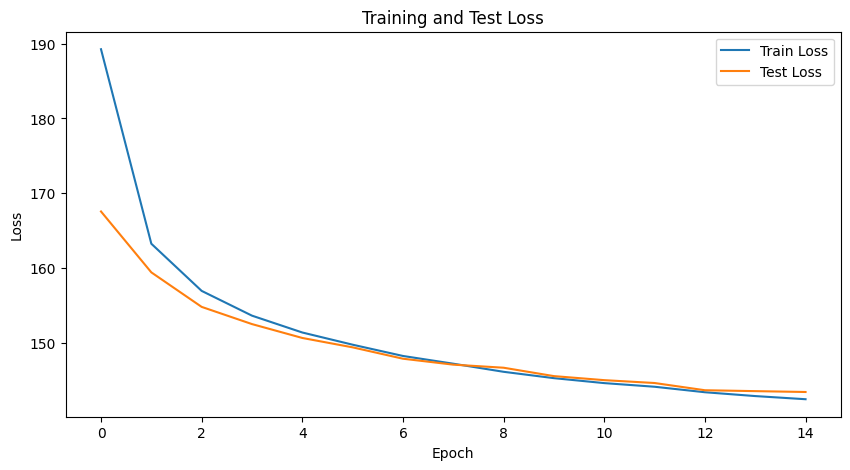

In [16]:
plt.figure(figsize=(10,5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Test Loss')
plt.show()

## 4. Генерация новых изображений

Теперь, когда модель обучена, мы можем генерировать новые цифры, просто подавая на вход декодеру случайные векторы $z \sim \mathcal{N}(0, I)$.

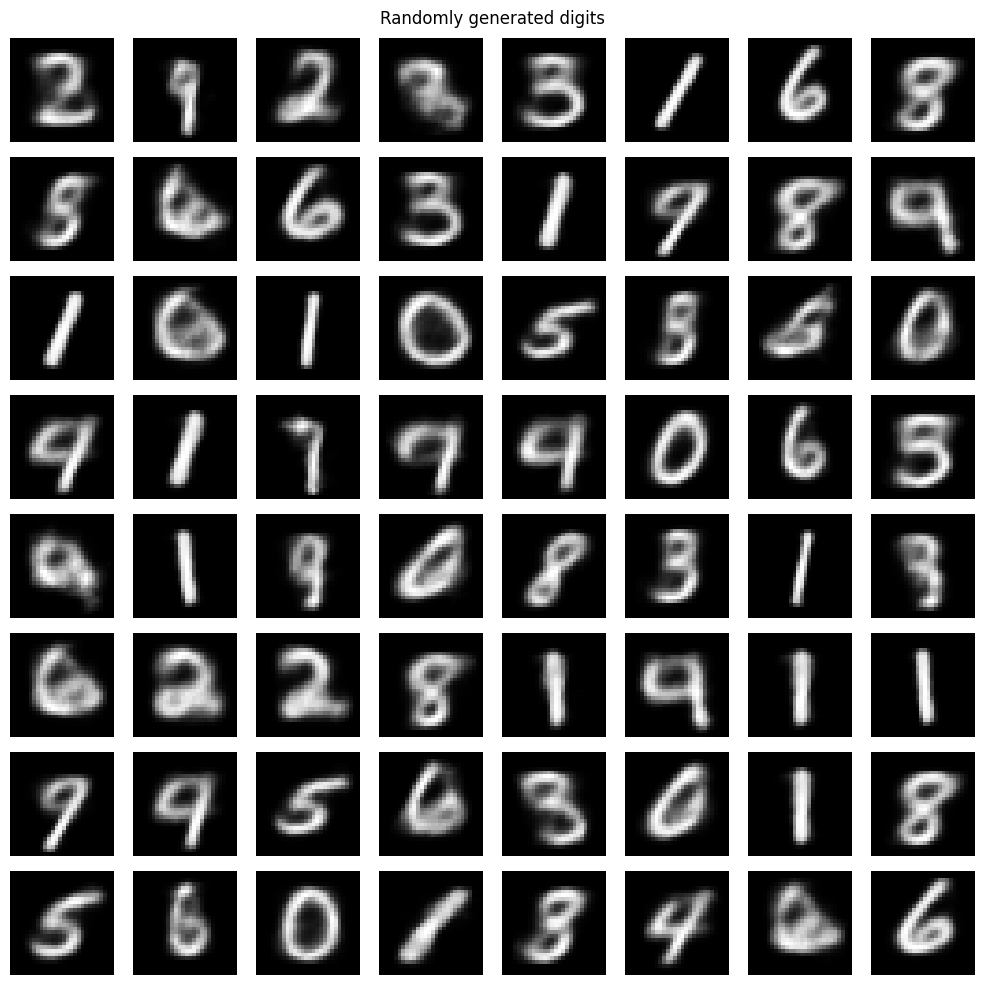

In [17]:
model.eval()
with torch.no_grad():
    # Генерируем 64 случайных z
    z = torch.randn(64, latent_dim).to(device)
    samples = model.decode(z).cpu().view(64, 28, 28)

plt.figure(figsize=(10,10))
for i in range(64):
    plt.subplot(8,8,i+1)
    plt.imshow(samples[i], cmap='gray')
    plt.axis('off')
plt.suptitle('Randomly generated digits')
plt.tight_layout()
plt.show()

## 5. Интерполяция в латентном пространстве

Возьмём два случайных изображения из тестового набора, найдём их латентные коды и линейно проинтерполируем между ними. Подадим промежуточные точки в декодер и посмотрим, как плавно меняется изображение.

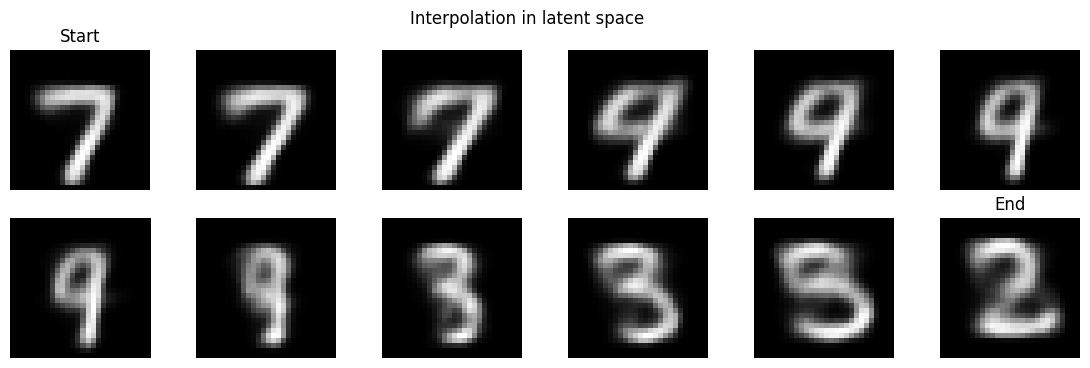

In [18]:
def interpolate(model, x1, x2, steps=10):
    """Линейная интерполяция между двумя изображениями в латентном пространстве."""
    model.eval()
    with torch.no_grad():
        x1 = x1.view(1, -1).to(device)
        x2 = x2.view(1, -1).to(device)
        mu1, _ = model.encode(x1)
        mu2, _ = model.encode(x2)
        # Интерполируем между mu1 и mu2
        alphas = np.linspace(0, 1, steps)
        interp_zs = torch.stack([(1-alpha)*mu1 + alpha*mu2 for alpha in alphas])
        interp_recon = model.decode(interp_zs).cpu().view(steps, 28, 28)
    return interp_recon

# Возьмём две случайные картинки из теста
test_iter = iter(test_loader)
images, labels = next(test_iter)
img1, img2 = images[0], images[1]

interp_images = interpolate(model, img1, img2, steps=12)

plt.figure(figsize=(14,4))
for i, img in enumerate(interp_images):
    plt.subplot(2,6,i+1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    if i == 0:
        plt.title('Start')
    elif i == len(interp_images)-1:
        plt.title('End')
plt.suptitle('Interpolation in latent space')
plt.show()

## 6. Визуализация латентного пространства (2D)

Уменьшим размерность латентного пространства до 2 (или используем t-SNE) и посмотрим, как распределены цифры.

Epoch 1, Loss: 162.7287
Epoch 2, Loss: 163.4839
Epoch 3, Loss: 162.4537
Epoch 4, Loss: 146.9598
Epoch 5, Loss: 153.3278


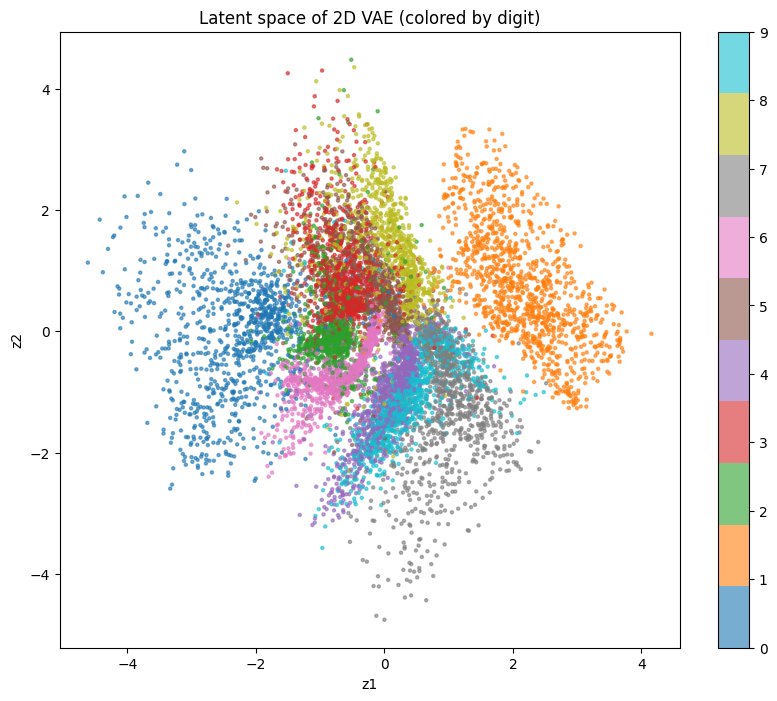

In [19]:
# Для визуализации обучим модель с latent_dim = 2 (или возьмём текущую и применим PCA/t-SNE)
# Но проще обучить маленькую модель с latent_dim=2, если есть время.
# Здесь мы просто покажем пример, как собрать латентные коды для тестовых данных.

model_2d = VAE(input_dim=784, hidden_dim=256, latent_dim=2).to(device)
optimizer_2d = optim.Adam(model_2d.parameters(), lr=1e-3)
# Обучим быстро 5 эпох (для демонстрации)
for epoch in range(5):
    model_2d.train()
    for data, _ in train_loader:
        data = data.view(data.size(0), -1).to(device)
        optimizer_2d.zero_grad()
        recon, mu, log_var = model_2d(data)
        loss = vae_loss(recon, data, mu, log_var)
        loss.backward()
        optimizer_2d.step()
    print(f'Epoch {epoch+1}, Loss: {loss.item():.4f}')

# Соберём латентные коды для тестовой выборки
model_2d.eval()
latent_codes = []
labels_list = []
with torch.no_grad():
    for data, target in test_loader:
        data = data.view(data.size(0), -1).to(device)
        mu, _ = model_2d.encode(data)
        latent_codes.append(mu.cpu().numpy())
        labels_list.append(target.numpy())
latent_codes = np.concatenate(latent_codes)
labels = np.concatenate(labels_list)

plt.figure(figsize=(10,8))
scatter = plt.scatter(latent_codes[:,0], latent_codes[:,1], c=labels, cmap='tab10', alpha=0.6, s=5)
plt.colorbar(scatter)
plt.xlabel('z1')
plt.ylabel('z2')
plt.title('Latent space of 2D VAE (colored by digit)')
plt.show()

## 7. **Задание для самостоятельной работы**:

Попробуйте модифицировать код и ответить на вопросы:<br>
4. **Другой датасет**: попробуйте обучить VAE на Fashion-MNIST или CIFAR-10 (для CIFAR-10 нужно перейти к цветным изображениям и использовать MSE или Gaussian decoder). Можно нейросетью изменения сгенерировать.

**По желанию:**
1. **β-VAE**: измените коэффициент `beta` в функции потерь на значения 0.1, 4, 10. Как меняются реконструкции и качество генерации? Почему?
2. **Размерность латентного пространства**: попробуйте `latent_dim = 2, 5, 50`. Как это влияет на качество реконструкции и гладкость интерполяций?
3. **Архитектура**: добавьте ещё один скрытый слой в энкодер/декодер или используйте сверточные слои (для этого потребуется изменить входные размеры).

👈 *Эти эксперименты помогут глубже понять, как работает VAE и какие факторы влияют на его поведение.*

In [20]:
# VAE на Fashion-MNIST
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt, numpy as np
from tqdm import tqdm

torch.manual_seed(42); np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.ToTensor()
train_ds = datasets.FashionMNIST('./data', train=True,  download=True, transform=transform)
test_ds  = datasets.FashionMNIST('./data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=128, shuffle=False, num_workers=2)

VAE (β=1, latent=20)
  ep 01: loss=296.19
  ep 02: loss=257.11
  ep 03: loss=250.99
  ep 04: loss=247.85
  ep 05: loss=246.09
  ep 06: loss=244.86
  ep 07: loss=243.89
  ep 08: loss=243.18
  ep 09: loss=242.50
  ep 10: loss=242.02
  ep 11: loss=241.65
  ep 12: loss=241.23
  ep 13: loss=240.94
  ep 14: loss=240.70
  ep 15: loss=240.44


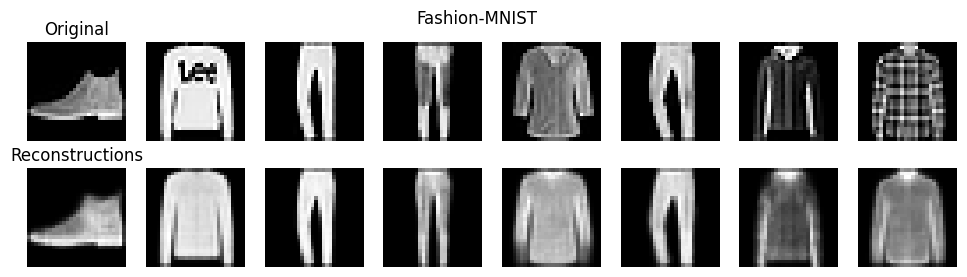

In [21]:
class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=256, latent_dim=20):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, 2 * latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, input_dim), nn.Sigmoid(),
        )
        self.latent_dim = latent_dim

    def encode(self, x):
        return self.encoder(x).chunk(2, dim=-1)

    def reparameterize(self, mu, log_var):
        return mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)

    def decode(self, z):
      return self.decoder(z)

    def forward(self, x):
        mu, lv = self.encode(x)
        return self.decode(self.reparameterize(mu, lv)), mu, lv

def vae_loss(recon, x, mu, lv, beta=1.0):
    bce = F.binary_cross_entropy(recon, x, reduction='sum')
    kl  = -0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp())
    return (bce + beta * kl) / x.size(0)

def train_vae(latent_dim=20, beta=1.0, epochs=15, hidden_dim=256):
    m = VAE(hidden_dim=hidden_dim, latent_dim=latent_dim).to(device)
    opt = optim.Adam(m.parameters(), lr=1e-3)
    for ep in range(epochs):
        m.train(); tot = 0
        for x, _ in train_loader:
            x = x.view(x.size(0), -1).to(device)
            opt.zero_grad()
            r, mu, lv = m(x)
            loss = vae_loss(r, x, mu, lv, beta)
            loss.backward(); opt.step()
            tot += loss.item() * x.size(0)
        print(f"  ep {ep+1:02d}: loss={tot/len(train_ds):.2f}")
    m.eval(); return m

print("VAE (β=1, latent=20)")
model = train_vae(latent_dim=20, beta=1.0, epochs=15)

x, _ = next(iter(test_loader)); x = x[:8].view(8, -1).to(device)
with torch.no_grad(): r, _, _ = model(x)
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0,i].imshow(x[i].cpu().view(28,28), cmap='gray'); axes[0,i].axis('off')
    axes[1,i].imshow(r[i].cpu().view(28,28), cmap='gray'); axes[1,i].axis('off')
axes[0,0].set_title('Original'); axes[1,0].set_title('Reconstructions')
plt.suptitle('Fashion-MNIST'); plt.show()

Модель уловила общую форму предметов (силуэты ботинок, брюк, футболок), хотя и теряет мелкие детали.

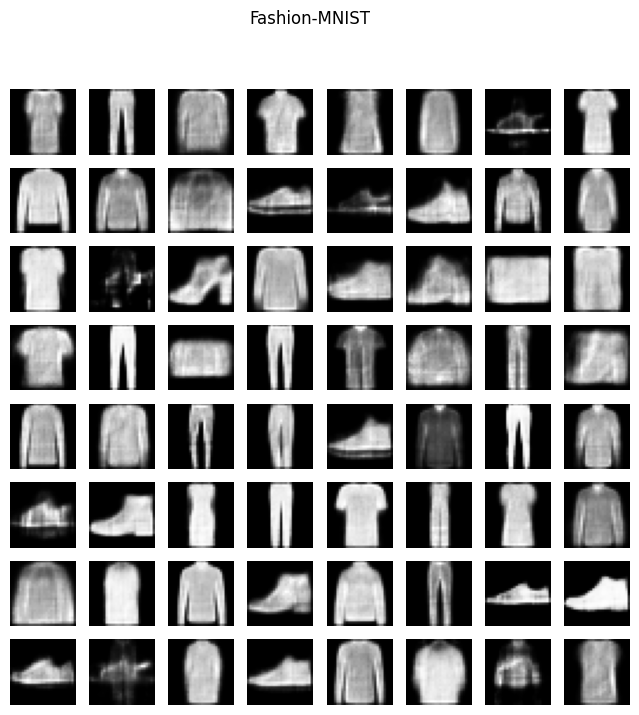

In [22]:
# генерация
with torch.no_grad():
    z = torch.randn(64, 20).to(device)
    samples = model.decode(z).cpu().view(64, 28, 28)
fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i], cmap='gray'); ax.axis('off')
plt.suptitle('Fashion-MNIST'); plt.show()

Модель создает правдоподобную одежду: кроссовки, ботинки, штаны, футболки, сумки.

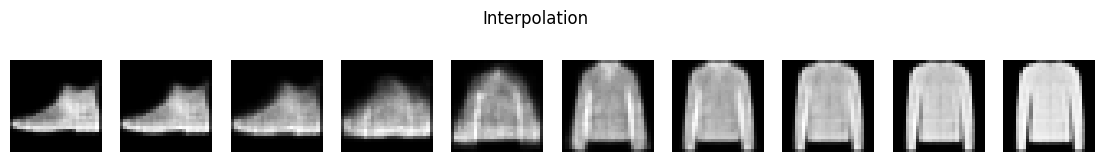

In [23]:
# интерполяция
with torch.no_grad():
    mu_a, _ = model.encode(x[0:1]); mu_b, _ = model.encode(x[1:2])
    alphas = np.linspace(0, 1, 10)
    zs = torch.cat([(1-a)*mu_a + a*mu_b for a in alphas], dim=0)
    interp = model.decode(zs).cpu().view(10, 28, 28)
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(interp[i], cmap='gray'); ax.axis('off')
plt.suptitle('Interpolation'); plt.show()


β-VAE sweep
beta=0.1
  ep 01: loss=279.44
  ep 02: loss=240.62
  ep 03: loss=233.31
  ep 04: loss=229.40
  ep 05: loss=226.94
beta=1.0
  ep 01: loss=295.34
  ep 02: loss=256.84
  ep 03: loss=250.45
  ep 04: loss=247.41
  ep 05: loss=245.80
beta=4.0
  ep 01: loss=318.00
  ep 02: loss=280.46
  ep 03: loss=274.57
  ep 04: loss=272.65
  ep 05: loss=271.43


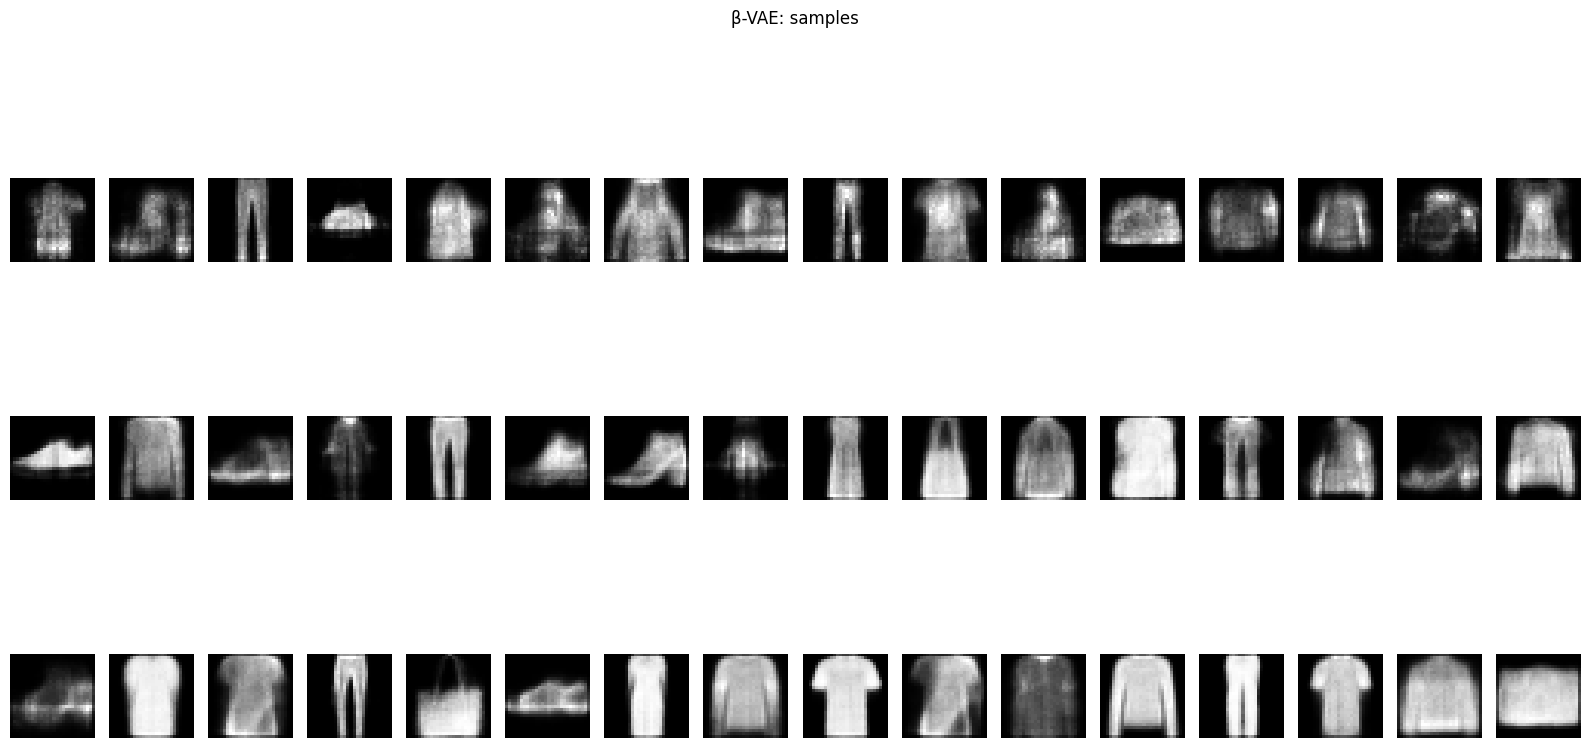

In [24]:
# β-VAE: 0.1, 1.0, 4.0
print("\nβ-VAE sweep")
betas = [0.1, 1.0, 4.0]
models_beta = {}
for b in betas:
    print(f"beta={b}")
    models_beta[b] = train_vae(latent_dim=20, beta=b, epochs=5)

# генерация сэмплов для сравнения
fig, axes = plt.subplots(len(betas), 16, figsize=(16, 3*len(betas)))
for row, b in enumerate(betas):
    with torch.no_grad():
        z = torch.randn(16, 20).to(device)
        s = models_beta[b].decode(z).cpu().view(16, 28, 28)
    for col in range(16):
        axes[row, col].imshow(s[col], cmap='gray'); axes[row, col].axis('off')
    axes[row, 0].set_ylabel(f"β={b}", rotation=0, labelpad=25, va='center')
plt.suptitle('β-VAE: samples'); plt.tight_layout(); plt.show()

Чем выше β, тем более предсказуемым становится латентное пространство, что лучше для генерации.

  ep 01: loss=296.97
  ep 02: loss=269.26
  ep 03: loss=265.53
  ep 04: loss=263.46
  ep 05: loss=262.04
  ep 06: loss=261.17
  ep 07: loss=260.36
  ep 08: loss=259.63
  ep 09: loss=259.35
  ep 10: loss=258.80
  ep 11: loss=258.24
  ep 12: loss=257.74
  ep 13: loss=257.54
  ep 14: loss=257.18
  ep 15: loss=256.91


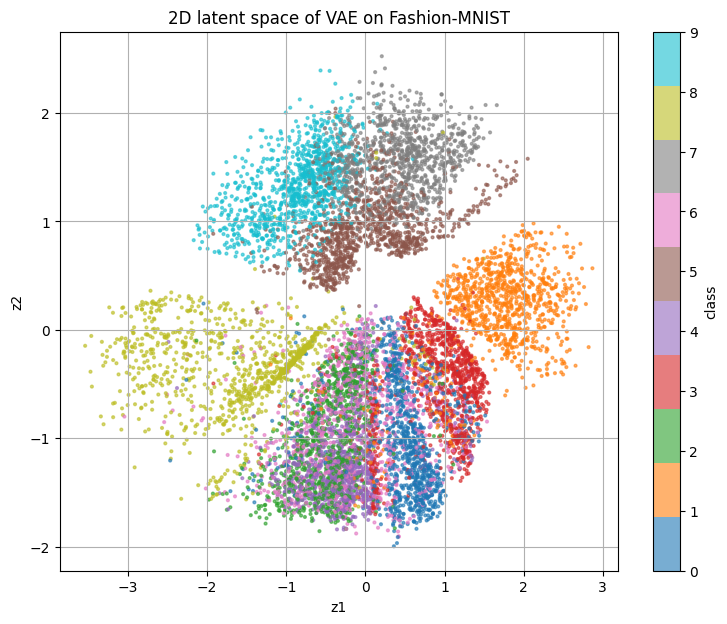

In [25]:
model_2d = train_vae(latent_dim=2, beta=1.0, epochs=15)

codes, labels = [], []
with torch.no_grad():
    for data, target in test_loader:
        data = data.view(data.size(0), -1).to(device)
        mu, _ = model_2d.encode(data)
        codes.append(mu.cpu().numpy()); labels.append(target.numpy())
codes = np.concatenate(codes); labels = np.concatenate(labels)
plt.figure(figsize=(9, 7))
sc = plt.scatter(codes[:,0], codes[:,1], c=labels, cmap='tab10', s=4, alpha=0.6)
plt.colorbar(sc, label='class'); plt.xlabel('z1'); plt.ylabel('z2')
plt.title('2D latent space of VAE on Fashion-MNIST'); plt.grid(True); plt.show()

Модель уловила основные различия, но для сложной одежды 2D-пространства не хватает.

## Заключение

Мы реализовали и обучили VAE на MNIST. Убедились, что модель способна:
- реконструировать входные изображения;
- генерировать новые правдоподобные цифры из случайного шума;
- выполнять плавные интерполяции в латентном пространстве;
- визуализировать структуру латентного пространства.

Это лишь базовый пример; современные VAE используются в самых разных задачах — от генерации изображений до моделирования молекул. Надеемся, что эксперименты помогут вам освоиться с этой техникой.

😊 *Удачных экспериментов!*